# Capítulo 5 · Actividad: ¿este tumor es benigno?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/03_actividad_breast_cancer_logistica.ipynb)

Entrena una **regresión logística** que diga si un tumor de mama es **benigno o maligno**. Haz el mismo proceso que en las actividades del Titanic y de los autos: primero entiende los datos y después elige el modelo. El preprocesamiento lo decides tú.

Cada fila es una muestra. De la imagen del núcleo celular se miden 10 cosas (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal). Cada una aparece tres veces:

| Grupo de columnas | Qué es |
|---|---|
| `mean ...` | Media de esa medida en la muestra |
| `... error` | Error estándar |
| `worst ...` | Media de los tres valores más grandes |
| `target` | **Target**: `0` = maligno, `1` = benigno |

`target` sale al revés de lo que uno esperaría: **1 es el caso benigno**.

Como mínimo, tu notebook debe incluir:

- La exploración de antes de modelar: forma de la tabla, balance de las dos clases, distribuciones, correlaciones y qué variables separan maligno de benigno.
- Una **regresión logística**. Las columnas no están en la misma escala (el área va por cientos y la suavidad por centésimas): decide si estandarizas.
- Métricas de **clasificación** con validación cruzada y en prueba. Como mínimo: accuracy, matriz de confusión y AUC. La accuracy sola engaña: hay más benignos que malignos.
- Tus **conclusiones**: qué modelo te quedas y por qué. Decir que un tumor maligno es benigno no es el mismo error al revés.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`


In [127]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "breast_cancer.csv")
df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [128]:
# Tu código aquí
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [129]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


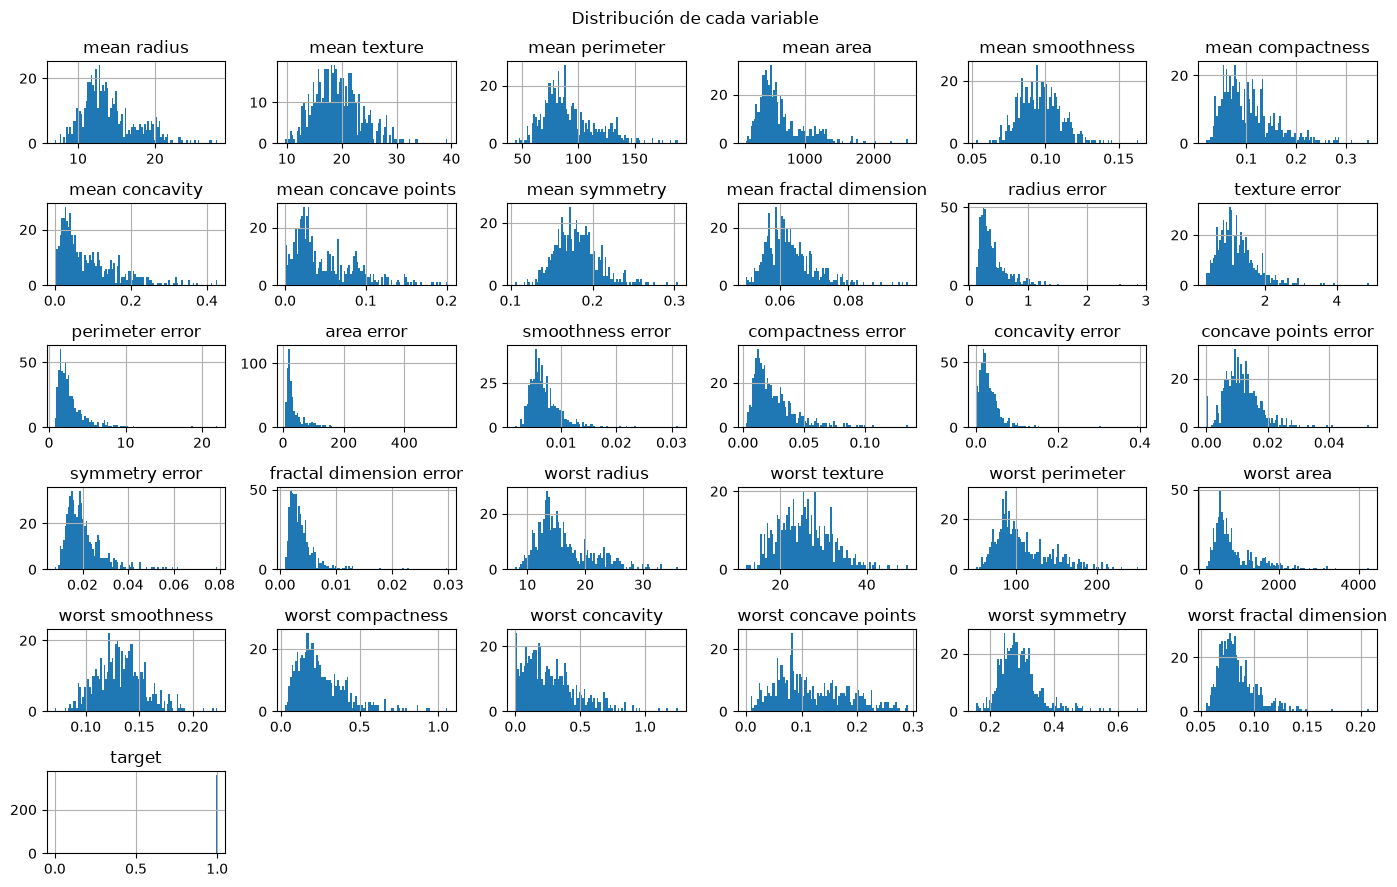

In [130]:
df.hist(bins=100, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

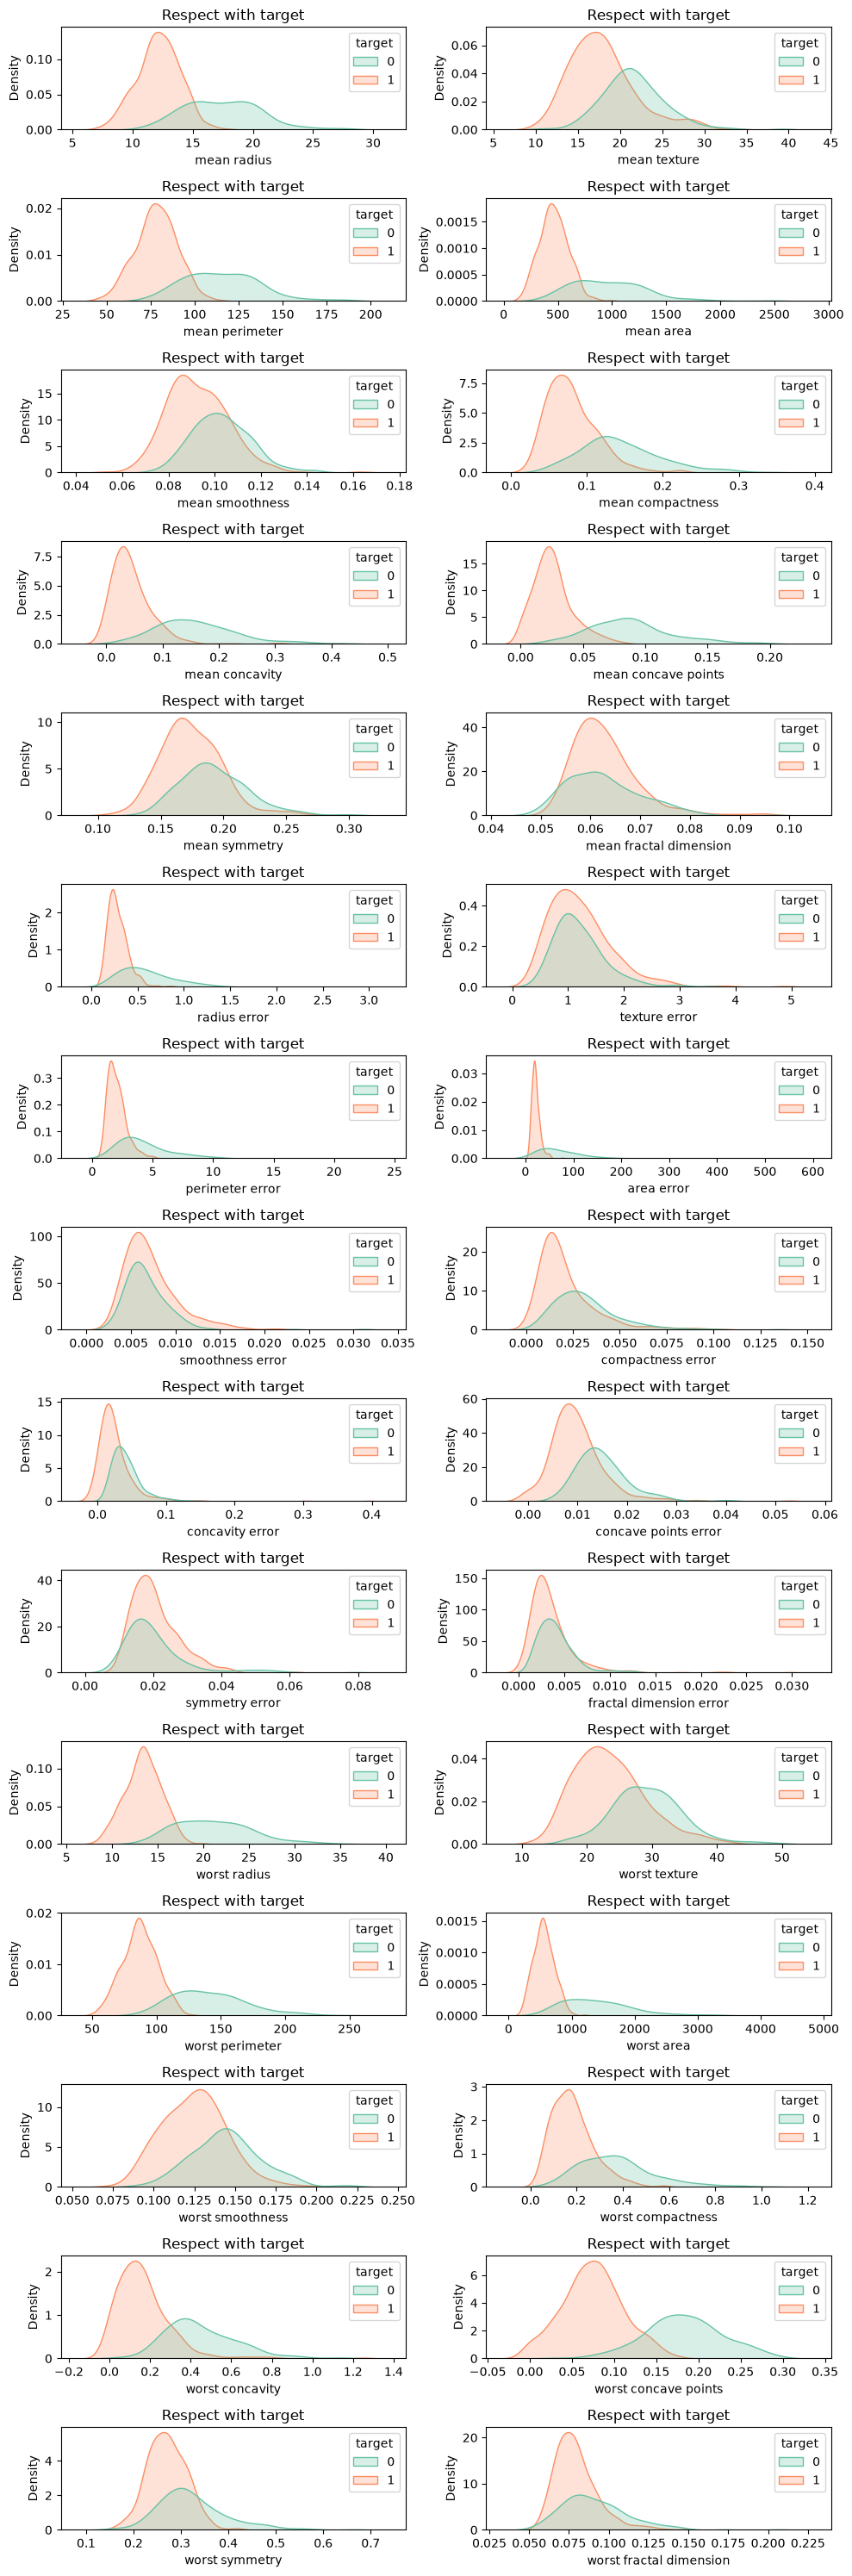

In [131]:
variables = df.columns

fig, axes = plt.subplots(15, 2,  figsize=(10,30))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="target", fill=True, palette="Set2", ax=ax)
    ax.set_title(f"Respect with target")
plt.tight_layout()
plt.show()

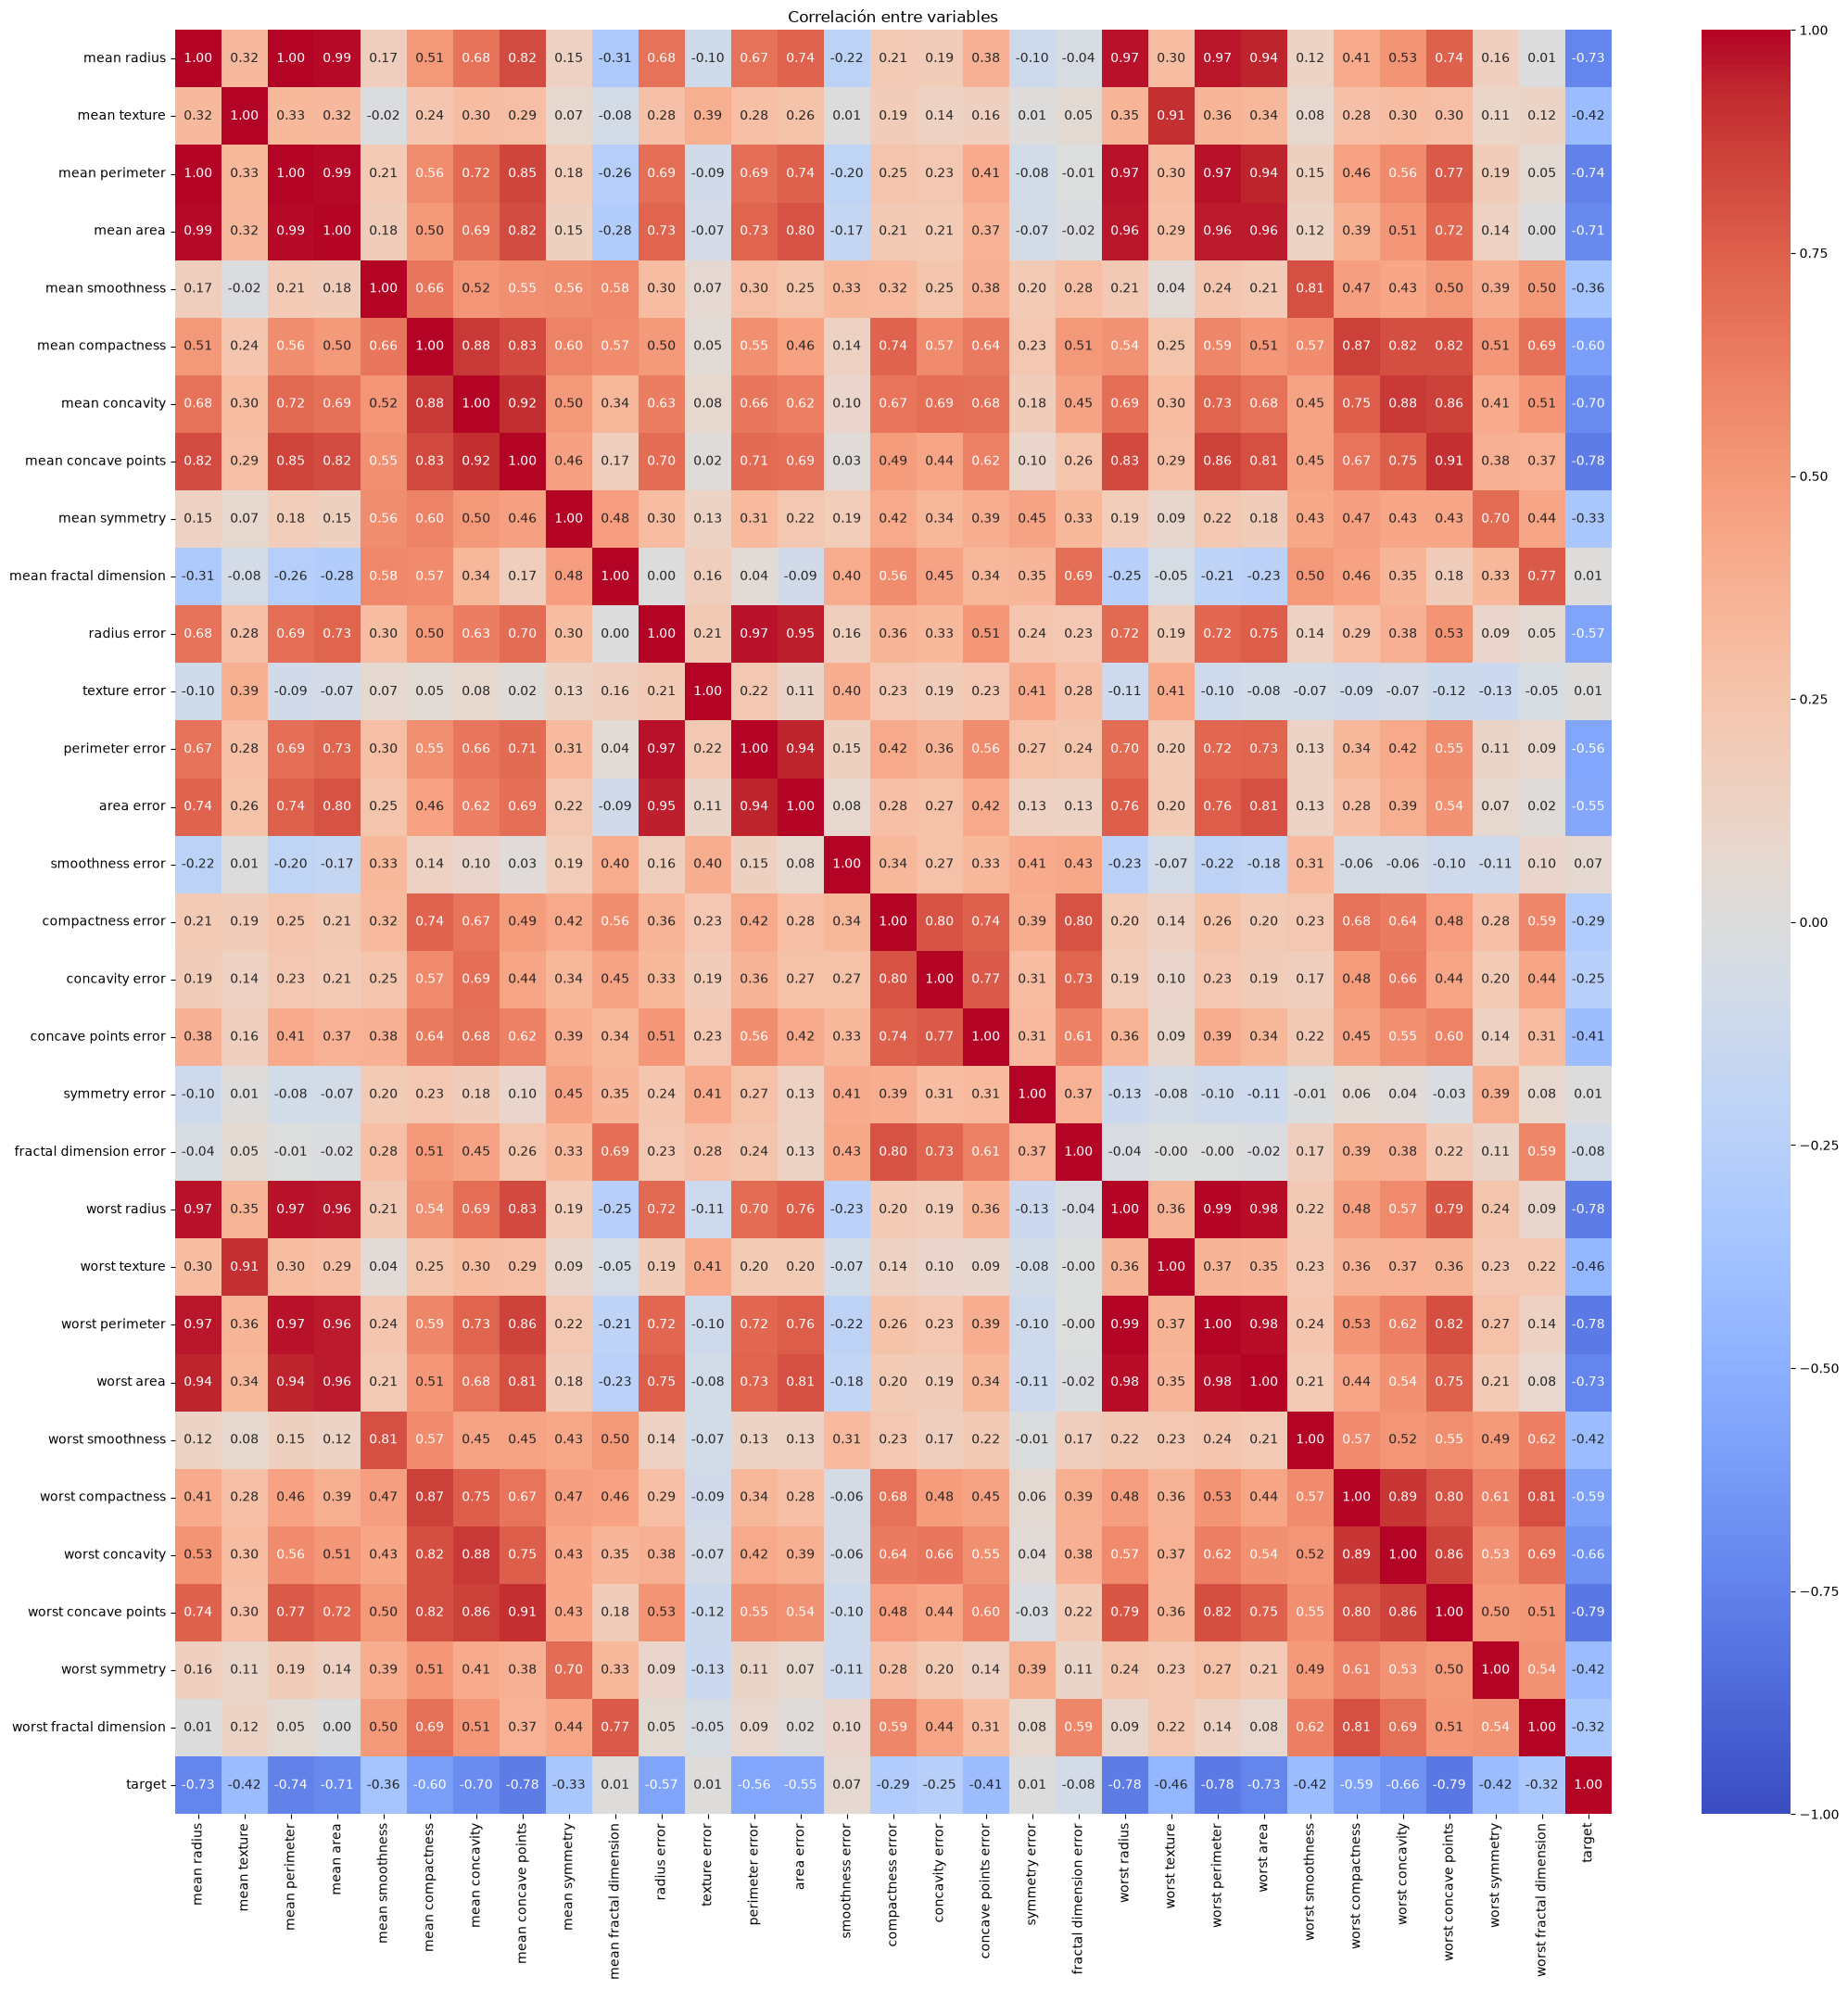

In [132]:
correlaciones = df[df.columns].corr()
plt.figure(figsize=(25,25))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

In [133]:
print(df.duplicated().sum())

0


In [134]:
df = df.drop(columns=["mean area","mean perimeter","area error", "perimeter error", "worst area", "worst perimeter","worst radius"])

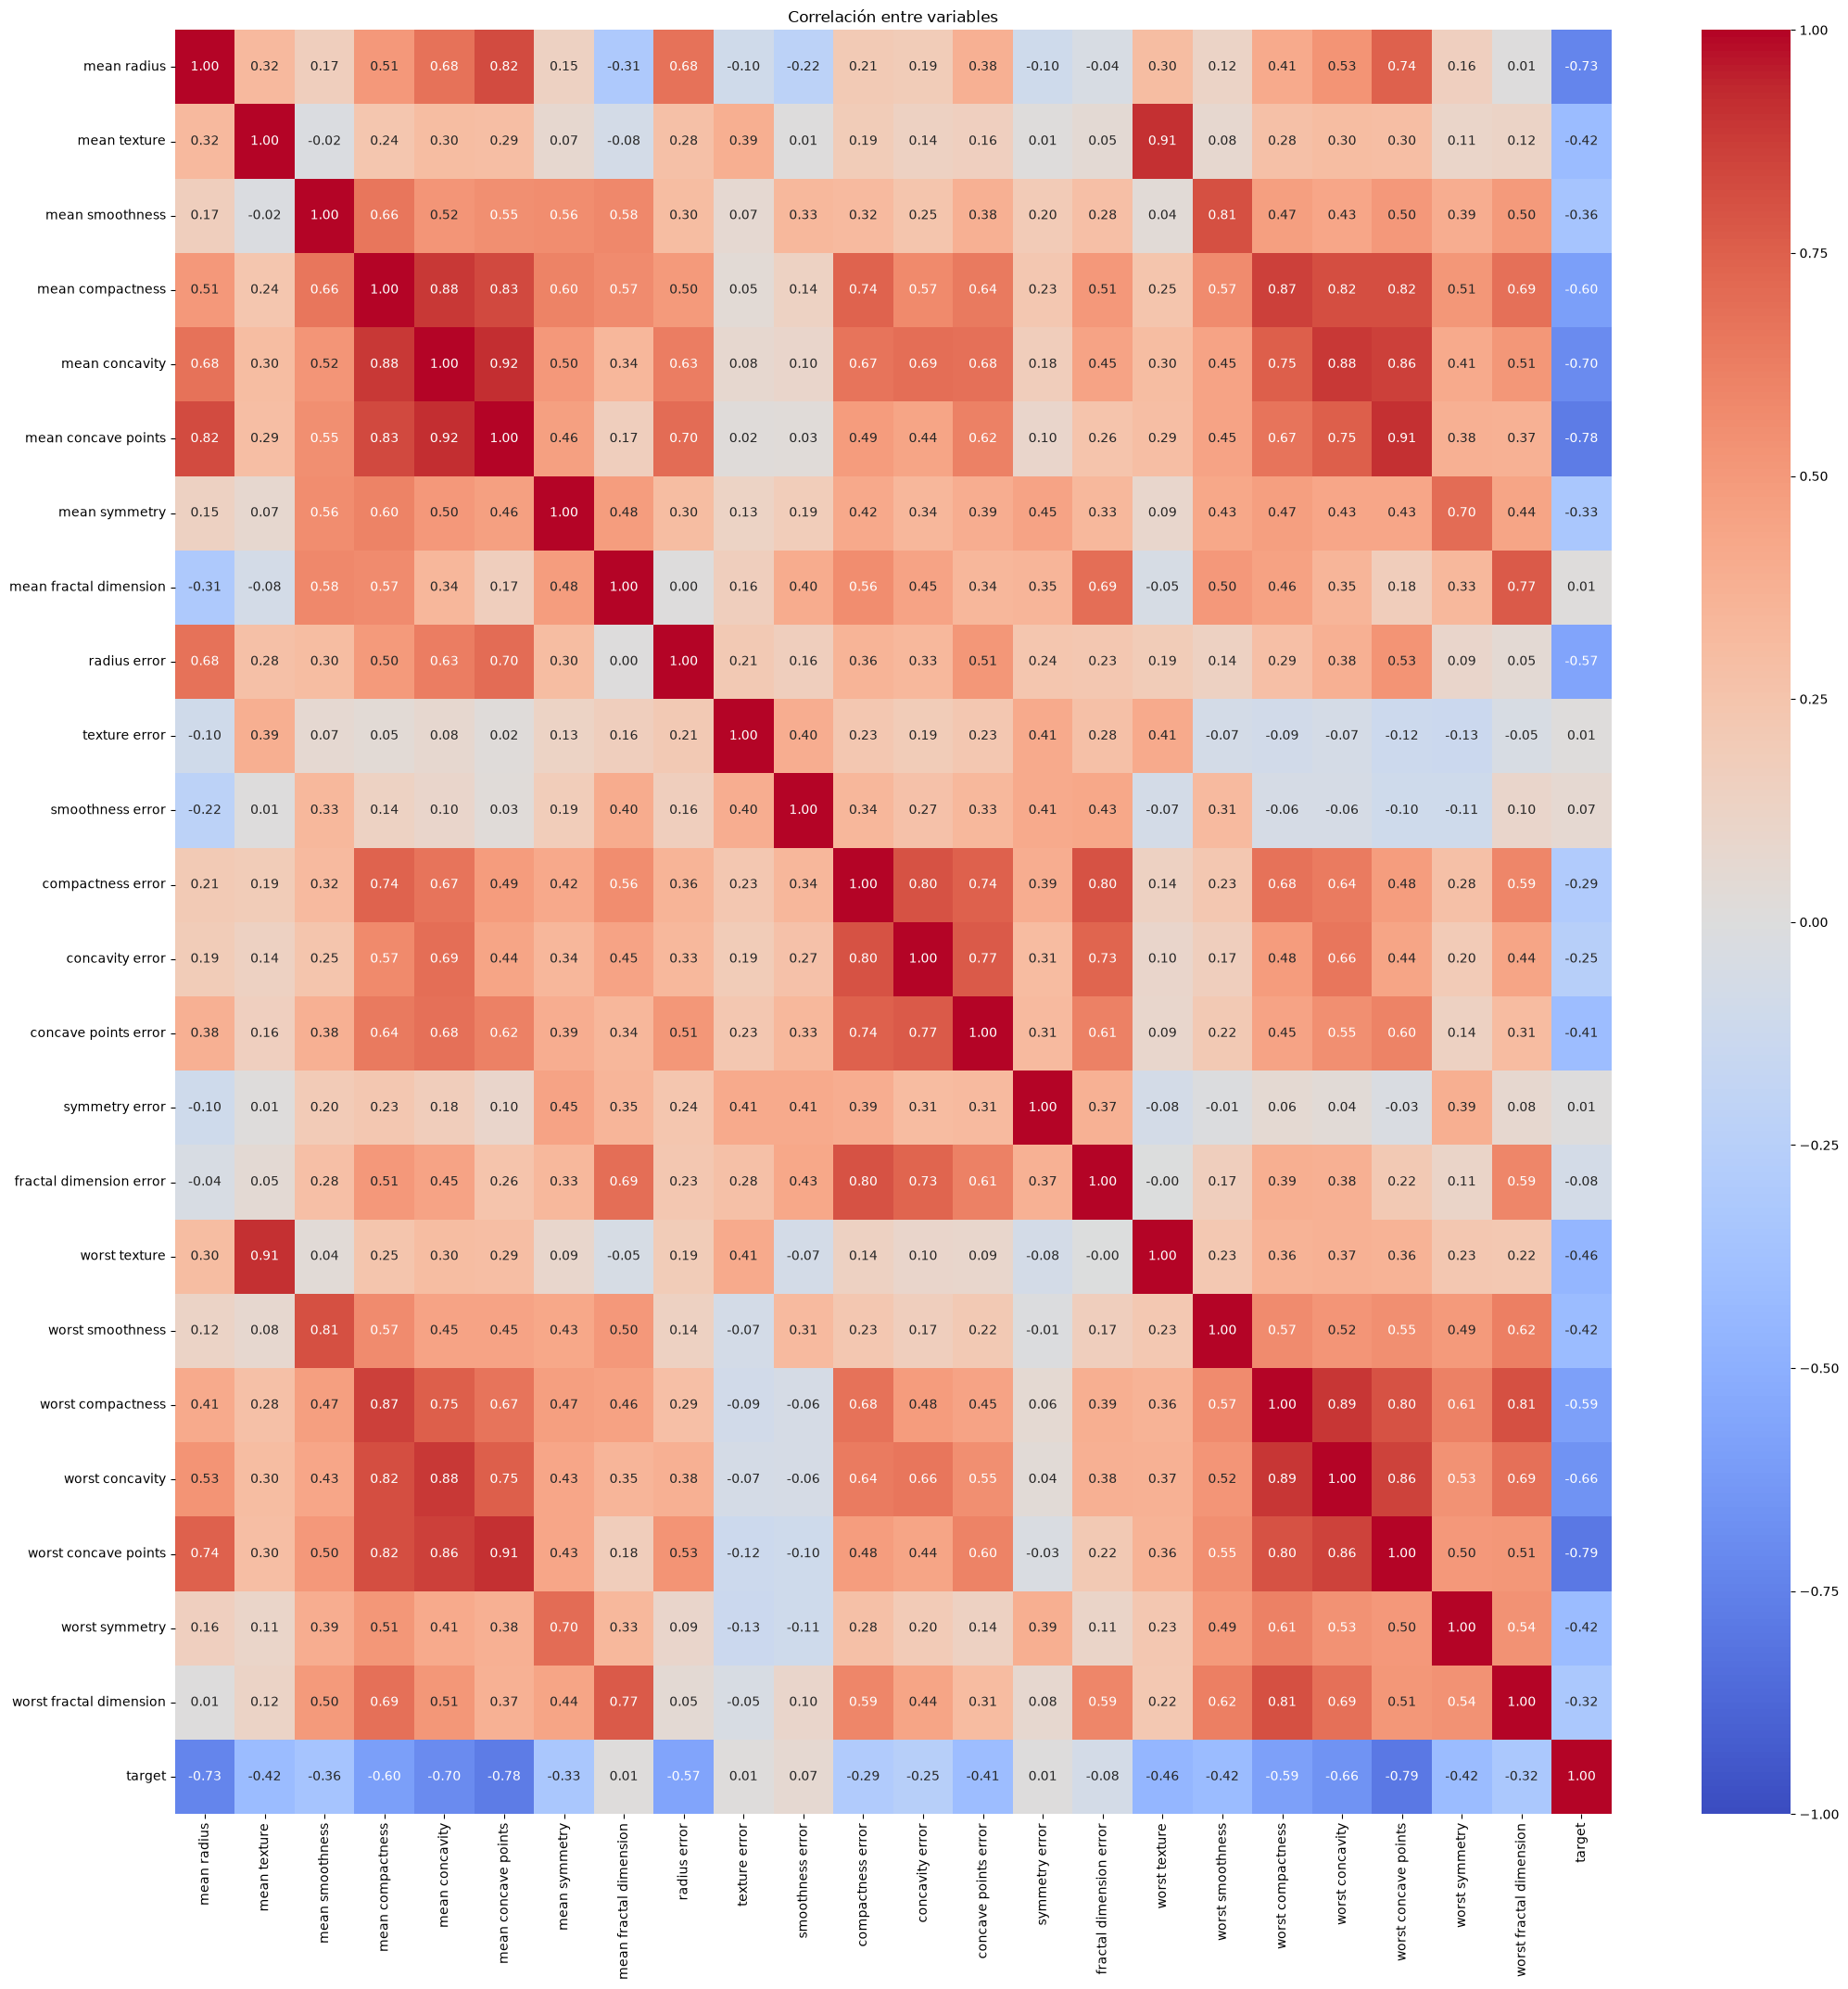

In [135]:
correlaciones = df[df.columns].corr()
plt.figure(figsize=(25,25))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

In [136]:
df = df.drop_duplicates().reset_index(drop=True)
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 23) | Test: (114, 23)


In [137]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

es_outlier = (X_train < limite_inferior) | (X_train > limite_superior)
es_outlier.sum()

mean radius                12
mean texture                7
mean smoothness             5
mean compactness           14
mean concavity             15
mean concave points         8
mean symmetry              14
mean fractal dimension     13
radius error               37
texture error              18
smoothness error           25
compactness error          25
concavity error            21
concave points error       17
symmetry error             25
fractal dimension error    22
worst texture               5
worst smoothness            3
worst compactness          15
worst concavity            10
worst concave points        0
worst symmetry             18
worst fractal dimension    20
dtype: int64

In [138]:
X_train = X_train.clip(lower=limite_inferior, upper=limite_superior, axis=1)
X_test = X_test.clip(lower=limite_inferior, upper=limite_superior, axis=1)

In [139]:
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("logistica", LogisticRegression()),
])
modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalador', ...), ('logistica', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['mean radius','mean texture','mean smoothness',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Accuracy en test: 95.6%
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        42
           1       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



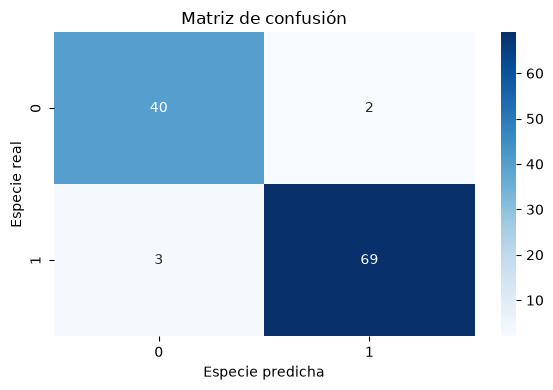

In [140]:
predicciones = modelo.predict(X_test)
print(f"Accuracy en test: {accuracy_score(y_test, predicciones):.1%}")
print(classification_report(y_test, predicciones, zero_division=0))

matriz = confusion_matrix(y_test, predicciones, labels=modelo.classes_)

plt.figure(figsize=(6, 4))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=modelo.classes_, yticklabels=modelo.classes_,
)
plt.xlabel("Especie predicha")
plt.ylabel("Especie real")
plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()

In [141]:
target = X_test.head()
pd.DataFrame(
    modelo.predict_proba(target), columns=modelo.classes_, index=target.index
).round(3)

,0,1
256,1.000,0.000
428,0.000,1.000
501,0.984,0.016
363,0.290,0.710
564,1.000,0.000
